<a href="https://colab.research.google.com/github/OlhaMir/testolha/blob/norma/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D1%80%D0%B5%D0%BD_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: класифікація у машинному навчанні

**Студент:** Мірошникова Ольга Ярославівна ФІТ 4-8


---



**До лекцій «Класифікація в МН», частини I та II**  
Робочі приклади: логістична регресія, KNN, Naive Bayes, SVM, дерево рішень, Random Forest, Gradient Boosting.  

**Мета:** виконати повний експеримент класифікації: від розбиття даних до оцінювання якості, порівняння алгоритмів і пояснення результатів. Усі приклади використовують вбудовані набори даних та стандартні бібліотеки `numpy`, `pandas`, `matplotlib`, `scikit-learn`.  
**Примітка:** навчальні набори не призначені для реальних медичних або інших високоризикових рішень.

## Частина I. Постановка задачі та базові класифікатори

Класифікація відрізняється від регресії тим, що цільова змінна є категоріальною. У першому прикладі будемо прогнозувати одну із двох міток (0 або 1) за числовими ознаками. Позитивним класом вважатимемо **1** — відповідно до кодування датасету.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score)

print('Імпорт бібліотек завершено.')

Імпорт бібліотек завершено.


### 1. Дані та відокремлення тестової вибірки

Датасет містить числові ознаки та дві категорії. `stratify=y` допомагає зберегти співвідношення класів у train і test. Тестова вибірка використовуватиметься тільки для оцінки вже побудованих навчальних моделей.

In [ ]:
dataset = load_breast_cancer()
X = dataset.data
y = dataset.target

print('Розмір матриці ознак:', X.shape)
print('Назви класів:', list(dataset.target_names))
print('Кількість об’єктів у класах:', dict(zip(*np.unique(y, return_counts=True))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Розмір матриці ознак: (569, 30)
Назви класів: [np.str_('malignant'), np.str_('benign')]
Кількість об’єктів у класах: {np.int64(0): np.int64(212), np.int64(1): np.int64(357)}
Train: (426, 30) Test: (143, 30)


In [ ]:
X_df = pd.DataFrame(X, columns=dataset.feature_names)
X_df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
df=pd.DataFrame(y, columns=['target'])
df['target'].value_counts()

,count
target,
1,357
0,212


In [ ]:
df

,target
0,0
1,0
2,0
3,0
4,0
...,...
564,0
565,0
566,0
567,0


### 2. Логістична регресія та матриця помилок

Застосовуємо `Pipeline`: масштаби ознак оцінюються виключно на train, що не допускає витоку інформації. На тестовій частині порівнюємо істинні та передбачені класи.

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        53
           1       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

Матриця помилок:
 [[52  1]
 [ 1 89]]


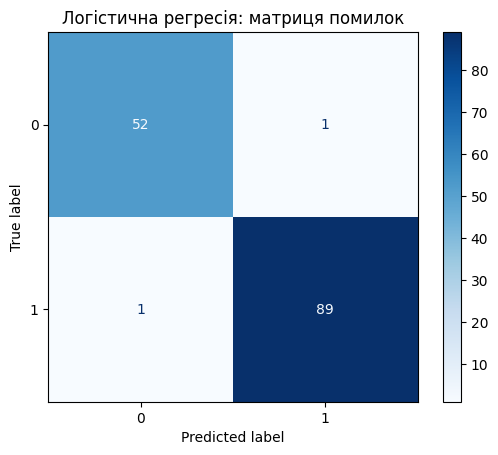

In [ ]:
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
logistic.fit(X_train, y_train)
y_pred_log = logistic.predict(X_test)

print(classification_report(y_test, y_pred_log, zero_division=0))
print('Матриця помилок:\n', confusion_matrix(y_test, y_pred_log))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_log, cmap='Blues')
plt.title('Логістична регресія: матриця помилок')
plt.show()

### 3. Імовірності та поріг рішення

Для бінарної моделі `predict_proba(X)[:, 1]` повертає оцінки ймовірності класу 1. За нижчого порога позитивних прогнозів зазвичай стає більше. Поріг у цьому прикладі досліджуємо **ілюстративно**, а не добираємо його за тестом для майбутнього застосування.

In [ ]:
probabilities = logistic.predict_proba(X_test)[:, 1]
rows = []
for threshold in [0.3, 0.5, 0.7]:
    pred = (probabilities >= threshold).astype(int)
    rows.append({'Поріг': threshold,
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred, zero_division=0)})
display(pd.DataFrame(rows).round(3))

,Поріг,Precision,Recall,F1
0,0.3,0.968,1.000,0.984
1,0.5,0.989,0.989,0.989
2,0.7,0.988,0.933,0.960


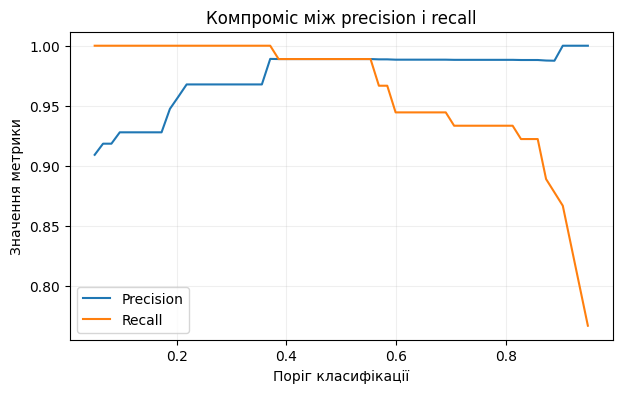

In [ ]:
thresholds = np.linspace(0.05, 0.95, 60)
p_scores = []
r_scores = []
for threshold in thresholds:
    pred = (probabilities >= threshold).astype(int)
    p_scores.append(precision_score(y_test, pred, zero_division=0))
    r_scores.append(recall_score(y_test, pred, zero_division=0))
plt.figure(figsize=(7, 4))
plt.plot(thresholds, p_scores, label='Precision')
plt.plot(thresholds, r_scores, label='Recall')
plt.xlabel('Поріг класифікації')
plt.ylabel('Значення метрики')
plt.title('Компроміс між precision і recall')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### 4. ROC і Precision–Recall криві

ROC візуалізує TPR та FPR при зміні порога. PR-крива показує співвідношення precision і recall; вона є особливо корисною, якщо позитивний клас рідкісний.

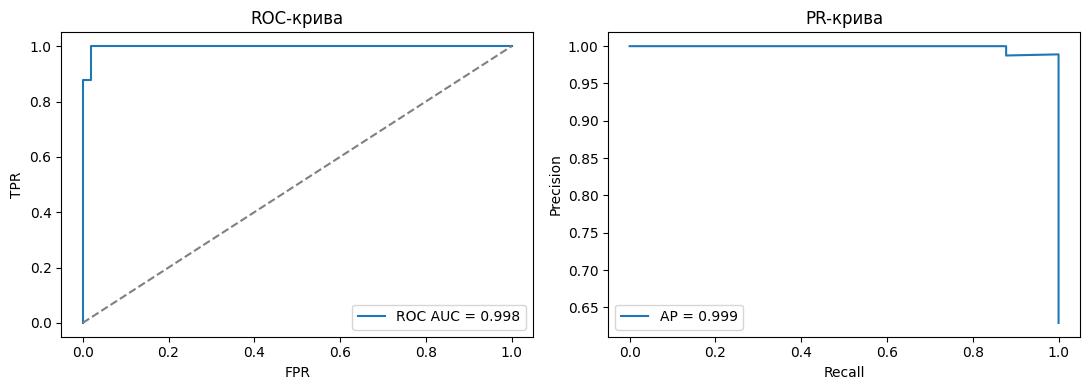

In [ ]:
fpr, tpr, _ = roc_curve(y_test, probabilities)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, probabilities)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f'ROC AUC = {roc_auc_score(y_test, probabilities):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='FPR', ylabel='TPR', title='ROC-крива')
axes[0].legend()

axes[1].plot(recall_curve, precision_curve,
             label=f'AP = {average_precision_score(y_test, probabilities):.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='PR-крива')
axes[1].legend()
plt.tight_layout()
plt.show()

### 5. Порівняння базових моделей

KNN використовує відстані між об’єктами, Naive Bayes — припущення про умовну незалежність ознак, SVM — роздільну межу з максимальним зазором. Для KNN і SVM застосовуємо стандартизацію всередині `Pipeline`. Всі моделі перевіряємо на тих самих об’єктах.

In [ ]:
models = {
    'Логістична регресія': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    'KNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Gaussian Naive Bayes': GaussianNB(),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0))
}
results = []
for name, current_model in models.items():
    current_model.fit(X_train, y_train)
    pred = current_model.predict(X_test)
    results.append({'Модель': name,
                    'Accuracy': accuracy_score(y_test, pred),
                    'Precision': precision_score(y_test, pred, zero_division=0),
                    'Recall': recall_score(y_test, pred, zero_division=0),
                    'F1': f1_score(y_test, pred, zero_division=0)})
comparison1 = pd.DataFrame(results).set_index('Модель').round(3)
display(comparison1)

,Accuracy,Precision,Recall,F1
Модель,,,,
Логістична регресія,0.986,0.989,0.989,0.989
KNN (k=5),0.979,0.968,1.000,0.984
Gaussian Naive Bayes,0.937,0.926,0.978,0.951
SVM (RBF),0.979,0.989,0.978,0.983


### 6. Стратифікована кросвалідація

Один поділ даних не відображає всього розкиду якості. Порівняємо моделі за п’ятьма однаковими навчальними складками. `cross_val_score` коректно перенавчає всі кроки пайплайна в кожній складці.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, current_model in models.items():
    scores = cross_val_score(current_model, X_train, y_train,
                             cv=cv, scoring='f1_macro')
    cv_rows.append({'Модель': name,
                    'CV F1 macro': scores.mean(),
                    'CV std': scores.std()})
display(pd.DataFrame(cv_rows).set_index('Модель').round(3))

,CV F1 macro,CV std
Модель,,
Логістична регресія,0.977,0.009
KNN (k=5),0.964,0.015
Gaussian Naive Bayes,0.937,0.036
SVM (RBF),0.965,0.005


### 7. Багатокласова класифікація на Iris

Iris має три класи, тому `classification_report` виводить метрики для кожного виду та способи їх усереднення. Для багатокласової задачі з однією міткою на об’єкт micro-F1 збігається з accuracy.

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



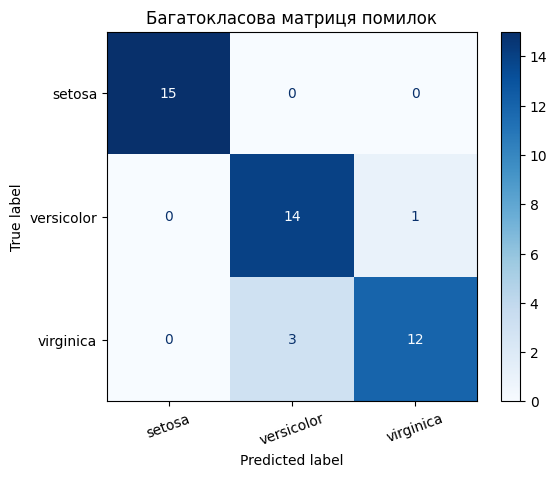

In [ ]:
iris = load_iris()

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    iris.data, iris.target, test_size=0.3, stratify=iris.target,
    random_state=42
)
multiclass = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
multiclass.fit(Xi_train, yi_train)
print(classification_report(yi_test, multiclass.predict(Xi_test),
                            target_names=iris.target_names))
ConfusionMatrixDisplay.from_estimator(multiclass, Xi_test, yi_test,
                                       display_labels=iris.target_names, cmap='Blues')
plt.xticks(rotation=20)
plt.title('Багатокласова матриця помилок')
plt.show()

## Частина II. Дерева рішень та ансамблі

Дерево рішень створює правила виду `ознака ≤ поріг`. Зменшення нечистоти (Gini або ентропії) визначає вибір умов у вузлах. Ансамблі поєднують прогнози багатьох дерев.

### 8. Індекс Джині: найпростіший ручний розрахунок

Для вузла з двома класами, де 60% об’єктів класу 0 та 40% класу 1, нечистота становить $G=1-0.6^2-0.4^2=0.48$. Для однорідного вузла вона дорівнює нулю.

In [ ]:
shares = np.array([0.6, 0.4])
gini = 1 - np.sum(shares ** 2)
print('Gini для часток 0.6 і 0.4:', round(gini, 2))

Gini для часток 0.6 і 0.4: 0.48


### 9. Навчання та візуалізація дерева рішень

Обмежуємо глибину, щоб правила були зрозумілими. Дерево не потребує масштабування числових ознак.

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.86      0.80      0.83        15
   virginica       0.81      0.87      0.84        15

    accuracy                           0.89        45
   macro avg       0.89      0.89      0.89        45
weighted avg       0.89      0.89      0.89        45



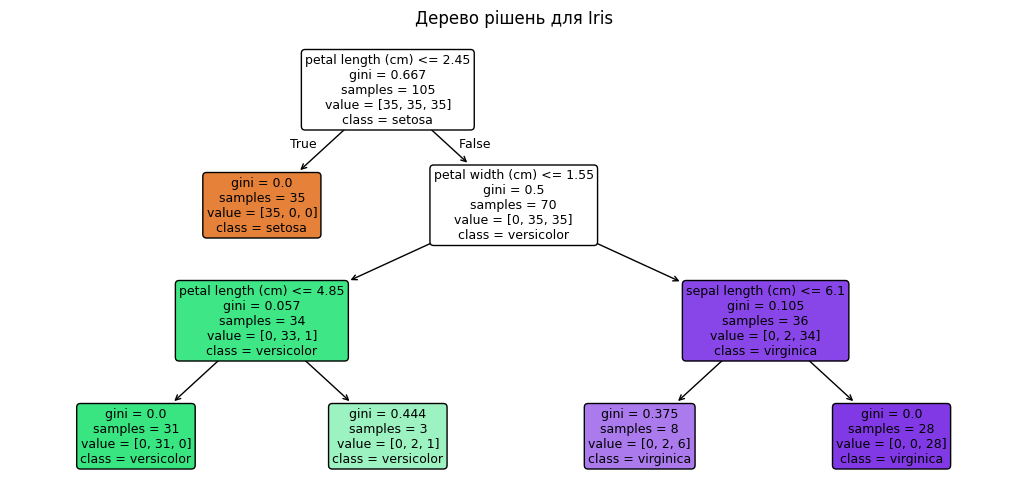

In [ ]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=3,
                              random_state=42)
tree.fit(Xi_train, yi_train)
print(classification_report(yi_test, tree.predict(Xi_test),
                            target_names=iris.target_names))
plt.figure(figsize=(13, 6))
plot_tree(tree, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True,
          rounded=True, fontsize=9)
plt.title('Дерево рішень для Iris')
plt.show()

### 10. Глибина дерева та перенавчання

Велика навчальна accuracy може поєднуватися з нижчою валідаційною оцінкою. Для підбору глибини застосовуємо кросвалідацію, не торкаючись тестової вибірки.

,Глибина,CV F1 macro
0,1,0.556
1,2,0.943
2,3,0.952
3,4,0.933
4,5,0.933
5,8,0.933


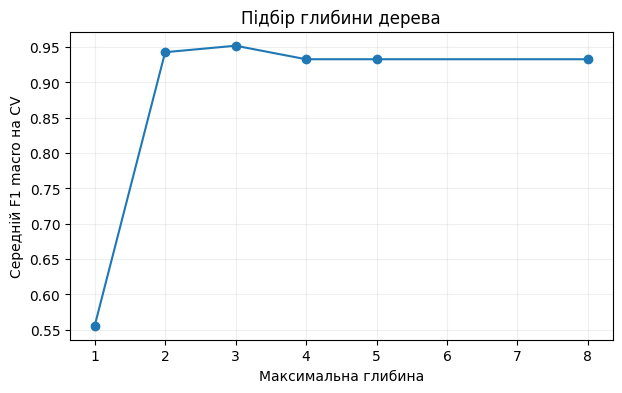

In [ ]:
depth_rows = []
for depth in [1, 2, 3, 4, 5, 8]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(candidate, Xi_train, yi_train,
                             cv=cv, scoring='f1_macro')
    depth_rows.append({'Глибина': depth, 'CV F1 macro': scores.mean()})
depth_table = pd.DataFrame(depth_rows)
display(depth_table.round(3))
plt.figure(figsize=(7, 4))
plt.plot(depth_table['Глибина'], depth_table['CV F1 macro'], marker='o')
plt.xlabel('Максимальна глибина')
plt.ylabel('Середній F1 macro на CV')
plt.title('Підбір глибини дерева')
plt.grid(alpha=0.2)
plt.show()

### 11. Random Forest і Gradient Boosting

У лісі багато дерев навчаються з випадковістю й результати усереднюються. Градієнтний бустинг додає дерева послідовно з метою зменшення функції втрат.

In [ ]:
ensemble_models = {
    'Дерево рішень': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150,
                                            min_samples_leaf=2, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100,
                                                    learning_rate=0.05,
                                                    max_depth=2, random_state=42)
}
ensemble_results = []
for name, current_model in ensemble_models.items():
    scores = cross_val_score(current_model, Xi_train, yi_train,
                             cv=cv, scoring='f1_macro')
    current_model.fit(Xi_train, yi_train)
    pred = current_model.predict(Xi_test)
    ensemble_results.append({'Модель': name, 'CV F1 macro': scores.mean(),
                             'Test F1 macro': f1_score(yi_test, pred, average='macro')})
display(pd.DataFrame(ensemble_results).set_index('Модель').round(3))

,CV F1 macro,Test F1 macro
Модель,,
Дерево рішень,0.952,0.978
Random Forest,0.962,0.911
Gradient Boosting,0.952,0.911


### 12. Налаштування дерева через GridSearchCV

У навчальній частині перевіримо невелику сітку гіперпараметрів. Після завершення кросвалідації перевіримо відібрану модель на тесті — без подальшого підбору за тестовим результатом.

In [ ]:
search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {'max_depth': [2, 3, 4, 5], 'min_samples_leaf': [1, 3, 5]},
    cv=cv, scoring='f1_macro'
)
search.fit(Xi_train, yi_train)
print('Найкращі гіперпараметри:', search.best_params_)
print('CV F1 macro:', round(search.best_score_, 3))
print('Test F1 macro:', round(f1_score(yi_test, search.predict(Xi_test),
                                      average='macro'), 3))

Найкращі гіперпараметри: {'max_depth': 3, 'min_samples_leaf': 1}
CV F1 macro: 0.952
Test F1 macro: 0.978


### 13. Важливість ознак (permutation importance)

Оцінюємо, наскільки змінюється точність уже навченої моделі після випадкового перемішування однієї ознаки. Це не причинний ефект. Наведена перевірка має демонстраційний характер: якщо важливість використовується для відбору ознак, її розраховують у валідаційному контурі.

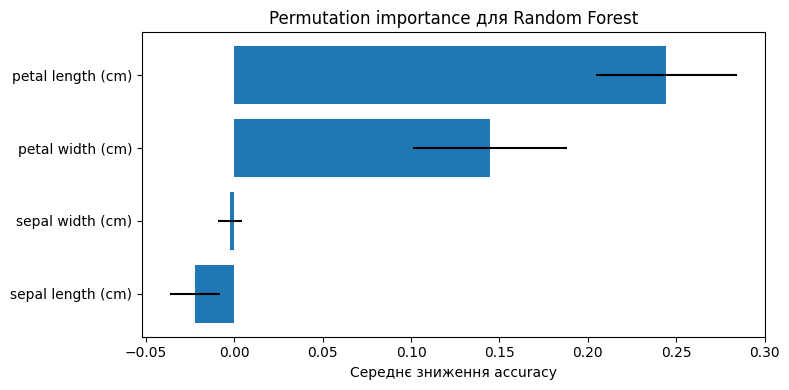

In [ ]:
forest = RandomForestClassifier(n_estimators=150, random_state=42)
forest.fit(Xi_train, yi_train)
importance = permutation_importance(
    forest, Xi_test, yi_test, scoring='accuracy',
    n_repeats=10, random_state=42
)
order = np.argsort(importance.importances_mean)
plt.figure(figsize=(8, 4))
plt.barh(np.array(iris.feature_names)[order],
         importance.importances_mean[order],
         xerr=importance.importances_std[order])
plt.xlabel('Середнє зниження accuracy')
plt.title('Permutation importance для Random Forest')
plt.tight_layout()
plt.show()

## Підсумок тренувальної роботи

Виконано завантаження та поділ даних, побудовано кілька класифікаторів, перевірено різницю метрик, застосовано кросвалідацію, створено дерево, ансамблі й графіки. Конкретні числові результати залежать від версій бібліотек; порівнювати моделі потрібно за узгодженими умовами, а не за одним випадковим показником.

## Самостійне завдання

**Тема: порівняння трьох класифікаторів на наборі Wine.** Використайте `load_wine()` зі `sklearn.datasets`. Самостійно виконайте всі етапи: стратифіковано поділіть дані на train/test (25% для тесту, `random_state=42`); навчіть **логістичну регресію, дерево рішень і Random Forest**; для логістичної регресії застосуйте стандартизацію тільки через `Pipeline`; порівняйте моделі за **macro-F1** з 5-блоковою стратифікованою кросвалідацією на train; для найкращої за CV моделі наведіть **матрицю помилок та classification report на test**. У висновку (5–7 речень) поясніть різницю між моделями та назвіть одну ознаку можливого перенавчання.

**Що здати:** заповнений ноутбук з кодом, виконаними комірками, графіком матриці помилок та текстовим висновком. Тестову вибірку не використовуйте для підбору моделі або гіперпараметрів. Нижче залишено комірку для Вашого самостійного розв’язання.

In [ ]:
# САМОСТІЙНЕ ЗАВДАННЯ
# Напишіть власний код для набору load_wine() згідно з умовою вище.
# Почніть з імпорту: from sklearn.datasets import load_wine

In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt

print("Імпорт бібліотек завершено.")

Імпорт бібліотек завершено.


In [2]:
wine = load_wine()

X = wine.data
y = wine.target

print("Розмір матриці ознак:", X.shape)
print("Назви ознак:", list(wine.feature_names))
print("Назви класів:", list(wine.target_names))
print("Кількість об'єктів у класах:",
      dict(zip(*__import__('numpy').unique(y, return_counts=True))))

Розмір матриці ознак: (178, 13)
Назви ознак: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Назви класів: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Кількість об'єктів у класах: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}


In [3]:
X_df = pd.DataFrame(X, columns=wine.feature_names)
X_df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [5]:
df=pd.DataFrame(y, columns=['target'])
df['target'].value_counts()

,count
target,
1,71
0,59
2,48


In [6]:
df

,target
0,0
1,0
2,0
3,0
4,0
...,...
173,2
174,2
175,2
176,2


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (133, 13)
Розмір тестової вибірки: (45, 13)


In [8]:
models = {
    "Логістична регресія": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Дерево рішень": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Створено три моделі класифікації.")

Створено три моделі класифікації.


In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro"
    )

    cv_results.append({
        "Модель": name,
        "Середній macro-F1": scores.mean(),
        "Стандартне відхилення": scores.std()
    })

comparison = pd.DataFrame(cv_results)
comparison = comparison.sort_values(
    by="Середній macro-F1",
    ascending=False
).reset_index(drop=True)

display(comparison.round(4))

,Модель,Середній macro-F1,Стандартне відхилення
0,Random Forest,0.9854,0.0292
1,Логістична регресія,0.9777,0.0182
2,Дерево рішень,0.9052,0.0537


In [10]:
best_name = comparison.loc[0, "Модель"]
best_model = models[best_name]

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("Найкраща модель за CV:", best_name)
print("Macro-F1 на тестовій вибірці:",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names,
    zero_division=0
))

Найкраща модель за CV: Random Forest
Macro-F1 на тестовій вибірці: 1.0

Classification report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



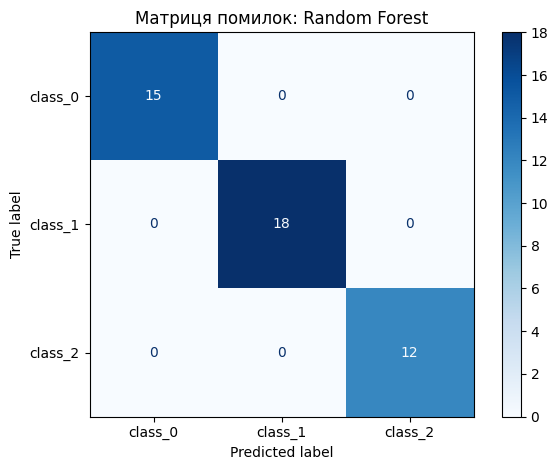

In [11]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=wine.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Матриця помилок: {best_name}")
plt.tight_layout()
plt.show()

**Висновок**

У ході роботи було виконано класифікацію набору даних Wine за допомогою логістичної регресії, дерева рішень і Random Forest. Дані було розділено на навчальну та тестову вибірки зі збереженням пропорцій класів. Для порівняння моделей використано п'ятиблокову стратифіковану кросвалідацію та метрику macro-F1. Найкращий результат за середнім macro-F1 під час кросвалідації показала модель **Random Forest**. На тестовій вибірці вона отримала macro-F1 = 1.00 та правильно класифікувала всі 45 об'єктів трьох класів. Логістична регресія потребує стандартизації ознак у цьому експерименті, тоді як дерево рішень і Random Forest можуть працювати без неї. Можливою ознакою перенавчання є суттєва різниця між результатами моделі на навчальних даних і під час кросвалідації, однак отриманий результат на тестовій вибірці сам по собі не свідчить про перенавчання.